# 네이버 웹툰 인기순 vs 조회순 상관관계 분석

네이버 웹툰 요일별 연재작의 **인기순 순위**와 **조회순 순위**가 얼마나 비슷한지 분석합니다.

| 정렬 | API 주소 |
|---|---|
| 인기순 | `https://comic.naver.com/api/webtoon/titlelist/weekday?order=user` |
| 조회순 | `https://comic.naver.com/api/webtoon/titlelist/weekday?order=view` |

> API가 조회수(`viewCount`)를 대부분 0으로 숨기기 때문에, 실제 조회수 대신 **순위 기반 상관계수**(Spearman, Kendall)를 사용합니다.

**분석 순서**
1. 라이브러리 불러오기
2. 데이터 불러오기
3. 두 순위 합치기 (병합 + 정규화)
4. 요일별 상관관계
5. 전체 상관관계
6. 순위 구간별 일치도
7. 별점과의 관계
8. 두 순위가 크게 갈리는 작품
9. 순위 차이의 원인 확인 (연재 기간)
10. 시각화

---
# 1단계. 라이브러리 불러오기

- `pandas`: 표 형태 데이터 처리
- `scipy.stats`: 상관계수 계산 (Spearman, Kendall)
- `matplotlib`: 그래프

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

# 그래프에서 한글이 깨지지 않도록 맑은 고딕 폰트 사용
plt.rcParams["font.family"] = "Malgun Gothic"
# 한글 폰트 사용 시 마이너스(-) 기호가 깨지는 문제 방지
plt.rcParams["axes.unicode_minus"] = False

# 노트북 파일이 있는 폴더 (raw_*.json 파일도 같은 폴더에 있음)
BASE = Path(".")

# 요일 순서를 고정하고, 영어 요일명을 한글 한 글자로 바꾸는 사전
DAYS = ["MONDAY", "TUESDAY", "WEDNESDAY", "THURSDAY", "FRIDAY", "SATURDAY", "SUNDAY"]
DAY_KO = dict(zip(DAYS, "월화수목금토일"))  # {'MONDAY': '월', 'TUESDAY': '화', ...}

---
# 2단계. 데이터 불러오기

API 응답(JSON) 구조는 다음과 같습니다.

```
{"titleListMap": {"MONDAY": [작품1, 작품2, ...], "TUESDAY": [...], ...}}
```

요일별 리스트는 **이미 정렬된 순서**로 들어 있으므로, 리스트 안의 위치(1, 2, 3, ...)가 곧 순위입니다.

In [2]:
def load(order):
    """저장해 둔 API 응답(raw_user.json / raw_view.json)을 읽어 순위 표로 만든다.

    order: 'user'(인기순) 또는 'view'(조회순)
    """
    raw = json.loads((BASE / f"raw_{order}.json").read_text(encoding="utf-8"))
    rows = []
    for day, items in raw["titleListMap"].items():
        # enumerate(..., 1): 리스트 위치를 1부터 세어 순위로 사용
        for i, x in enumerate(items, 1):
            rows.append({
                "day": day,
                "titleId": x["titleId"],        # 작품 고유 번호 (클수록 최근 등록)
                "titleName": x["titleName"],    # 작품명
                "starScore": x["starScore"],    # 별점
                "new": x["new"],                # 신작 여부
                "rest": x["rest"],              # 휴재 여부
                f"rank_{order}": i,             # 해당 요일 안에서의 순위
            })
    return pd.DataFrame(rows)


pop = load("user")   # 인기순
view = load("view")  # 조회순

print("인기순 작품 수:", len(pop))
print("조회순 작품 수:", len(view))
pop.head()

인기순 작품 수: 846
조회순 작품 수: 846


,day,titleId,titleName,starScore,new,rest,rank_user
0,WEDNESDAY,769209,화산귀환,9.86750,False,False,1
1,WEDNESDAY,816809,별을 품은 소드마스터,9.97358,False,False,2
2,WEDNESDAY,846109,싸이코패스 in 무림,9.87241,False,False,3
3,WEDNESDAY,838002,종말이 찾아왔다,9.85762,False,False,4
4,WEDNESDAY,854589,조의 영역: 여의도,9.77241,False,False,5


In [3]:
# 참고: viewCount(조회수)가 실제로 공개된 작품은 몇 편인지 확인
raw_view = json.loads((BASE / "raw_view.json").read_text(encoding="utf-8"))
visible = sum(x["viewCount"] > 0 for items in raw_view["titleListMap"].values() for x in items)
print(f"조회수가 공개된 작품: {visible}편 / 전체 {len(view)}편")
print("→ 조회수 대신 '순위'로 분석한다.")

조회수가 공개된 작품: 16편 / 전체 846편
→ 조회수 대신 '순위'로 분석한다.


---
# 3단계. 두 순위 합치기 (병합 + 정규화)

- **병합**: `(요일, titleId)`를 기준으로 인기순 표와 조회순 표를 합칩니다.
  (같은 작품이 여러 요일에 연재되면 요일마다 따로 셉니다.)
- **정규화**: 요일마다 작품 수가 달라(116~136편) 순위를 그대로 비교하기 어렵습니다.
  그래서 순위를 **0~1 백분위**로 바꿉니다. (0 = 1위, 1 = 꼴찌)
- **순위차(`gap`)** = 조회순 순위 − 인기순 순위
  - `+` : 인기에 비해 조회순이 낮음
  - `−` : 인기에 비해 조회순이 높음

In [4]:
# 조회순 표에서는 순위 열만 가져와 병합 (작품명·별점은 인기순 표에 이미 있음)
view_rank = view[["day", "titleId", "rank_view"]]
df = pop.merge(view_rank, on=["day", "titleId"], how="inner").rename(columns={"rank_user": "rank_pop"})

# 요일별 작품 수
df["n"] = df.groupby("day")["titleId"].transform("count")

# 백분위 순위: (순위 - 1) / (작품 수 - 1) → 1위는 0, 꼴찌는 1
df["pct_pop"] = (df["rank_pop"] - 1) / (df["n"] - 1)
df["pct_view"] = (df["rank_view"] - 1) / (df["n"] - 1)

# 순위차
df["gap"] = df["rank_view"] - df["rank_pop"]
df["day_ko"] = df["day"].map(DAY_KO)

# 병합 결과 저장 (엑셀에서 한글이 깨지지 않도록 utf-8-sig)
df.to_csv(BASE / "webtoon_rank_merged.csv", index=False, encoding="utf-8-sig")

print("병합된 작품 수:", len(df))
df.head()

병합된 작품 수: 846


,day,titleId,titleName,starScore,new,rest,rank_pop,rank_view,n,pct_pop,pct_view,gap,day_ko
0,WEDNESDAY,769209,화산귀환,9.86750,False,False,1,1,116,0.000000,0.000000,0,수
1,WEDNESDAY,816809,별을 품은 소드마스터,9.97358,False,False,2,2,116,0.008696,0.008696,0,수
2,WEDNESDAY,846109,싸이코패스 in 무림,9.87241,False,False,3,8,116,0.017391,0.060870,5,수
3,WEDNESDAY,838002,종말이 찾아왔다,9.85762,False,False,4,3,116,0.026087,0.017391,-1,수
4,WEDNESDAY,854589,조의 영역: 여의도,9.77241,False,False,5,7,116,0.034783,0.052174,2,수


---
# 4단계. 요일별 상관관계

요일마다 두 순위가 얼마나 같은 순서인지 계산합니다.

| 지표 | 의미 |
|---|---|
| **Spearman ρ** | 순위끼리의 상관계수. 1에 가까울수록 두 순위가 같음 |
| **Kendall τ** | 작품 두 편을 골랐을 때 두 기준의 앞뒤 순서가 같은 정도 |
| **Top10 / Top30 겹침** | 두 기준 상위 10위(30위) 안에 공통으로 든 작품 수 |
| **순위차 중앙값** | 두 순위 차이(절댓값)의 중앙값 |

In [5]:
rows = []
for day in DAYS:
    g = df[df["day"] == day]  # 해당 요일 작품만

    # 상관계수와 p값 (p값이 작을수록 '우연히 나온 결과가 아님')
    rho, p_rho = stats.spearmanr(g["rank_pop"], g["rank_view"])
    tau, p_tau = stats.kendalltau(g["rank_pop"], g["rank_view"])

    # 상위 N위 겹침: 두 기준 상위 N위 작품 집합의 교집합 크기
    top10 = len(set(g.nsmallest(10, "rank_pop").titleId) & set(g.nsmallest(10, "rank_view").titleId))
    top30 = len(set(g.nsmallest(30, "rank_pop").titleId) & set(g.nsmallest(30, "rank_view").titleId))

    rows.append({
        "요일": DAY_KO[day],
        "작품수": len(g),
        "Spearman": round(rho, 3),
        "Kendall": round(tau, 3),
        "p(Spearman)": f"{p_rho:.1e}",
        "Top10 겹침": top10,
        "Top30 겹침": top30,
        "|순위차| 중앙값": int(g["gap"].abs().median()),
    })

by_day = pd.DataFrame(rows)
by_day

,요일,작품수,Spearman,Kendall,p(Spearman),Top10 겹침,Top30 겹침,|순위차| 중앙값
0,월,124,0.952,0.825,1.8e-64,8,29,5
1,화,120,0.934,0.804,1.2e-54,6,26,4
2,수,116,0.943,0.823,3.6e-56,8,25,4
3,목,116,0.969,0.864,2.1e-71,8,27,4
4,금,117,0.943,0.826,1.4e-56,8,25,5
5,토,136,0.901,0.754,2.2e-50,5,26,7
6,일,117,0.943,0.810,6.2e-57,8,25,5


> **해석**: 모든 요일에서 ρ ≥ 0.90 → 두 순위는 매우 강하게 일치합니다.
> 목요일이 가장 일치하고(0.969), 토요일이 가장 덜 일치합니다(0.901).

---
# 5단계. 전체 상관관계 (요일 통합)

요일마다 작품 수가 다르므로, 3단계에서 만든 **백분위 순위**로 846편 전체를 한 번에 비교합니다.

In [6]:
rho_all, p_all = stats.spearmanr(df["pct_pop"], df["pct_view"])
tau_all, _ = stats.kendalltau(df["pct_pop"], df["pct_view"])

print(f"Spearman ρ = {rho_all:.3f} (p = {p_all:.1e})")
print(f"Kendall  τ = {tau_all:.3f}")
# Kendall τ를 '두 작품의 순서가 같을 확률'로 바꾸면 (1 + τ) / 2
print(f"→ 임의의 두 작품의 앞뒤 순서가 두 기준에서 같을 확률 ≈ {(1 + tau_all) / 2:.0%}")

Spearman ρ = 0.940 (p = 0.0e+00)
Kendall  τ = 0.808
→ 임의의 두 작품의 앞뒤 순서가 두 기준에서 같을 확률 ≈ 90%


---
# 6단계. 순위 구간별 일치도

상위권·중위권·하위권 중 어디에서 두 순위가 더 많이 엇갈리는지 확인합니다.
(구간은 인기순 백분위 기준)

In [7]:
bands = []
for lo, hi, name in [(0, .2, "상위 20%"), (.2, .5, "20~50%"), (.5, 1.01, "하위 50%")]:
    g = df[(df["pct_pop"] >= lo) & (df["pct_pop"] < hi)]
    r, _ = stats.spearmanr(g["pct_pop"], g["pct_view"])
    bands.append({
        "인기순 구간": name,
        "작품수": len(g),
        "Spearman": round(r, 3),
        # 두 백분위 순위의 평균 차이 (0.034 = 평균 3.4%p 차이)
        "|백분위차| 평균": round((g["pct_pop"] - g["pct_view"]).abs().mean(), 3),
    })

bands = pd.DataFrame(bands)
bands

,인기순 구간,작품수,Spearman,|백분위차| 평균
0,상위 20%,170,0.844,0.034
1,20~50%,252,0.682,0.073
2,하위 50%,424,0.807,0.074


> **해석**: 상위권은 거의 같고, **중위권(20~50%)** 에서 순서가 가장 많이 뒤섞입니다.

---
# 7단계. 별점과의 관계 (참고)

별점이 높은 작품이 순위도 높은지 확인합니다.
순위는 작을수록 상위이므로 부호를 뒤집어(`-`) **양수 = 별점 높은 작품이 상위**가 되도록 맞춥니다.

In [8]:
rho_star_pop, _ = stats.spearmanr(df["starScore"], df["pct_pop"])
rho_star_view, _ = stats.spearmanr(df["starScore"], df["pct_view"])

print(f"별점 vs 인기순 ρ = {-rho_star_pop:.3f}")
print(f"별점 vs 조회순 ρ = {-rho_star_view:.3f}")
print()
print("별점 분포:")
df["starScore"].describe().round(2)

별점 vs 인기순 ρ = 0.163
별점 vs 조회순 ρ = 0.235

별점 분포:


count    846.00
mean       9.76
std        0.51
min        2.75
25%        9.78
50%        9.89
75%        9.94
max        9.98
Name: starScore, dtype: float64

> **해석**: 상관이 약합니다. 별점이 대부분 9.8~9.9점대에 몰려 있어 작품 간 차이를 거의 설명하지 못합니다.

---
# 8단계. 두 순위가 크게 갈리는 작품

순위차(`gap`)가 가장 큰 작품들을 양방향으로 10편씩 뽑습니다.

In [9]:
cols = ["day_ko", "titleName", "rank_pop", "rank_view", "gap", "starScore", "new", "rest"]

# gap이 가장 작은(음수) 작품 = 조회순이 인기순보다 훨씬 높음
view_over = df.nsmallest(10, "gap")[cols]
print("▶ 조회순이 인기순보다 훨씬 높은 작품")
view_over

▶ 조회순이 인기순보다 훨씬 높은 작품


,day_ko,titleName,rank_pop,rank_view,gap,starScore,new,rest
728,토,아사,136,43,-93,9.95538,False,False
560,금,몽홀,85,5,-80,9.89325,False,True
181,화,윌유메리미,66,6,-60,9.91454,False,False
82,수,하렘의 남자들,83,30,-53,9.94832,False,False
698,토,멸망한 세계의 취사병,106,57,-49,9.81573,False,False
692,토,마법사가 죽음을 맞이하는 방법,100,52,-48,9.95573,False,False
61,수,언덕 위의 제임스,62,15,-47,9.91222,False,False
642,토,윌유메리미,50,4,-46,9.91454,False,False
407,월,히어로메이커,56,11,-45,9.89575,False,False
279,목,최강전설 강해효,44,2,-42,9.54743,False,False


In [10]:
# gap이 가장 큰(양수) 작품 = 인기순이 조회순보다 훨씬 높음
pop_over = df.nlargest(10, "gap")[cols]
print("▶ 인기순이 조회순보다 훨씬 높은 작품")
pop_over

▶ 인기순이 조회순보다 훨씬 높은 작품


,day_ko,titleName,rank_pop,rank_view,gap,starScore,new,rest
163,화,끓는 점,48,100,52,9.88625,True,False
634,토,메이드,42,83,41,9.94365,True,False
636,토,주식토피아,44,85,41,9.66904,True,False
685,토,상향혼 컨설팅,93,131,38,9.72895,True,False
182,화,시골 다방에 요괴들이 와요,67,103,36,9.86528,True,False
420,월,첫사랑 트랩,69,103,34,9.90149,True,False
680,토,내가 키운 남주가 집착한다,88,122,34,9.90514,True,False
802,일,몰락민족의 천재 기사,74,108,34,9.77076,True,False
37,수,초월무제,38,71,33,9.74072,True,False
780,일,인터뷰,52,84,32,9.88617,False,False


> **관찰**: 조회순이 높은 쪽에는 오래된 작품·휴재작(`rest=True`)이,
> 인기순이 높은 쪽에는 신작(`new=True`)이 많이 보입니다. → 9단계에서 수치로 확인

---
# 9단계. 순위 차이의 원인 확인 (연재 기간)

가설: **조회순 ≈ 누적 조회수**, **인기순 ≈ 최근 반응**

- 맞다면 최신 작품(`titleId`가 클수록)은 인기순이 더 높고(백분위 순위차 `+`)
- 오래된 작품·휴재작은 조회순이 더 높아야(백분위 순위차 `−`) 합니다.

In [11]:
# 백분위 순위차: + 면 인기순이 더 높음, - 면 조회순이 더 높음
df["pct_gap"] = df["pct_view"] - df["pct_pop"]

# ① titleId(등록 순서)와 순위차의 상관
r, p = stats.spearmanr(df["titleId"], df["pct_gap"])
print(f"titleId vs 백분위 순위차: Spearman ρ = {r:.3f} (p = {p:.1e})")
print()

# ② 신작 / 휴재작 그룹별 평균 순위차
print("[신작 여부별 평균 백분위 순위차]")
print(df.groupby("new")["pct_gap"].agg(["count", "mean"]).round(3))
print()
print("[휴재 여부별 평균 백분위 순위차]")
print(df.groupby("rest")["pct_gap"].agg(["count", "mean"]).round(3))

titleId vs 백분위 순위차: Spearman ρ = 0.424 (p = 2.9e-38)

[신작 여부별 평균 백분위 순위차]
       count   mean
new                
False    782 -0.009
True      64  0.106

[휴재 여부별 평균 백분위 순위차]
       count   mean
rest               
False    802  0.005
True      44 -0.084


> **해석**
> - 최신 작품일수록 인기순이 조회순보다 앞서는 경향 (ρ ≈ 0.42)
> - 신작은 평균 **+10.6%p** (인기순이 더 높음), 휴재작은 평균 **−8.4%p** (조회순이 더 높음)
> - 가설과 일치: 조회순은 누적, 인기순은 최근 반응을 반영하는 것으로 보입니다. (네이버 공식 기준이 아닌 추정)

---
# 10단계. 시각화

- **왼쪽**: 인기순(x) vs 조회순(y) 백분위 산점도. 점선 위에 있으면 두 순위가 같은 작품
- **오른쪽**: 요일별 Spearman 상관계수

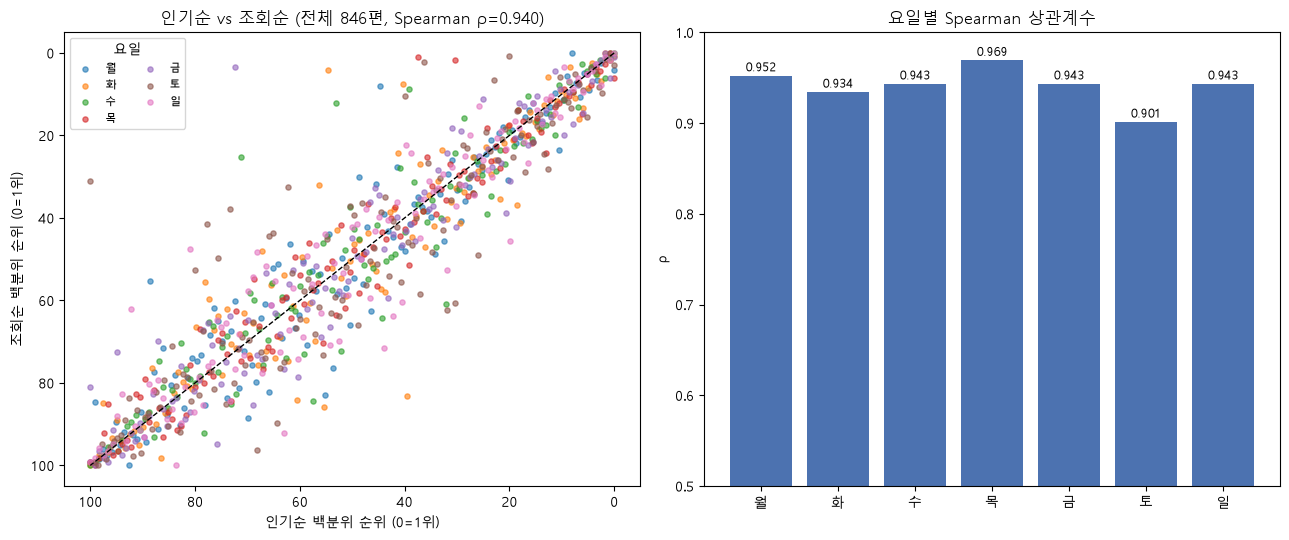

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# 왼쪽: 산점도 (요일별 색 구분, 0~100 백분위로 표시)
for day in DAYS:
    g = df[df["day"] == day]
    axes[0].scatter(g["pct_pop"] * 100, g["pct_view"] * 100, s=14, alpha=.6, label=DAY_KO[day])
axes[0].plot([0, 100], [0, 100], "k--", lw=1)  # 두 순위가 같은 기준선
axes[0].set(xlabel="인기순 백분위 순위 (0=1위)", ylabel="조회순 백분위 순위 (0=1위)",
            title=f"인기순 vs 조회순 (전체 {len(df)}편, Spearman ρ={rho_all:.3f})")
axes[0].invert_xaxis(); axes[0].invert_yaxis()  # 1위가 오른쪽 위에 오도록 축 뒤집기
axes[0].legend(title="요일", fontsize=8, ncol=2)

# 오른쪽: 요일별 상관계수 막대그래프
axes[1].bar(by_day["요일"], by_day["Spearman"], color="#4C72B0")
for i, v in enumerate(by_day["Spearman"]):
    axes[1].text(i, v + .005, f"{v:.3f}", ha="center", fontsize=9)  # 막대 위에 값 표시
# 값 차이가 잘 보이도록 y축을 0.5부터 시작
axes[1].set(ylim=(min(.5, by_day["Spearman"].min() - .05), 1), title="요일별 Spearman 상관계수", ylabel="ρ")

plt.tight_layout()
plt.savefig(BASE / "rank_corr.png", dpi=130)
plt.show()

---
# 결론

1. 인기순과 조회순은 **매우 강하게 일치** (전체 ρ = 0.94, 모든 요일 ρ ≥ 0.90)
2. 상위권은 거의 같고, **중위권에서 가장 많이 엇갈림**
3. 차이의 주된 원인은 **연재 기간**
   - 오래된 작품·휴재작 → 조회순이 더 높음 (누적 효과)
   - 신작 → 인기순이 더 높음 (최근 반응)
4. 별점은 두 순위와 거의 관계없음

자세한 내용은 `naver_webtoon_EDA_report.md` 참고